# Pandas

Today we are going to really start using pandas.  Lets review the libraries or packages and what they have done so far.
2.  we import matplotlib.pyplot as plt.  This turns on all the graphing capabilities and then uses the shorthand plt. for when we call functions from matplotlib.  This used to be called pylab but was updated to pyplot.  Then we say fig,ax=plt.subplots() and all the plot functions go into fig and ax
3.  we import numpy as np.  This turns on math functions and we use the shorthand np.
4.  from scipy we import stats.  scipy gives us a lot of analysis functions and we use linear regression from stats.
5.  Now we are also going to use pandas.  Pandas is database management. It stands for panel data  It lets us take complicated datasets and anlyze them.  You can think of it like a supercharged excel where you combine the organization of excel with the power of a programming language.  It can do amazing things and I am still learning every day.  So lets get started!
1.  What is pandas? http://pandas.pydata.org/index.html  and here is the documentation http://pandas.pydata.org/pandas-docs/stable/
1.  import pandas as pd!!!!!!
1.  On a final note you can see I made a numbered list in markdown. To do that you type a number a period and then two spaces.
1.  Also in terms of line numnbers.  I turn my line numbers on so it is easier to debug.  Do this under view


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(legacy='1.25') #removes the funny printing

## Importing files
We are going to start by finding our csv file and reading it in

Today we are going to look at data from well water chemistry in Bangladesh. Specifically arsenic concentrations and if people drink the water.  We will also look at the rest of the chemistry.  We are looking at well water arsenic because drinking water with arsenic has negative long term health impacts.  The US standard for arsenic is 10 ppb or 10 ug/L.  The bangladesh standard is 50 ppb.  Lets see what we can learn!  We are going to try and learn about how many people drink water with 10 or 50 ppb arsenic.   

But we are going to read in some data and try to analyze it.  open the well_data.csv.  It is for wells from Bangladesh. every well has an 
- id#
- latitude
- longitude
- Depth
- if people drink from it 
- concentration data.  

lets use readcsv to get read in.  In Pandas you are trying to get your data into a dataframe which is like an excel sheet.  It will have column titles and an index for rows.  It is all about the dataframes.  When using pandas people name things 'df' a lot.  That is shorthand for dataframe.  I am not a good namer.   

I am going to just name it df today.  

In [2]:
df=pd.read_csv('well_data.csv')

The data is now magically in the computers memory even if we can't see it we can access it!

## This is important.  Your output may not look like my output.  It changes between computers depending on default settings when you installed.  Don't worry.  If you see data of descriptions you are fine.

just typing well_data will give us some descriptions of what we got!  It used the first row for column names!  

In [3]:
df

,Well_ID,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,...,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
0,2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,...,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
4,84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
754,12516,24.71,90.41,160,Y,32379.64000,0.197380,3669.430000,39790.24000,0.341200,...,26.299280,13.330000,1850.53,0.340000,0.13000,331.900000,0.3976,57.0935,10.4236,0.0391
755,12654,24.36,91.27,60,Y,25561.12000,0.090570,13771.370000,57630.63000,1.498350,...,19.723360,33.740000,3958.51,1.200000,17.39000,215.750000,NaN,NaN,NaN,NaN
756,72641,24.38,90.90,45,N,31319.48000,1.162550,38.300000,60905.16000,22.417560,...,14.114910,21.700000,3372.45,1.560000,112.37000,251.660000,0.2567,35.4774,0.1471,0.0363
757,76175,23.90,90.65,60,N,30605.53000,1.556120,4168.520000,66756.16000,12.793100,...,33.180360,25.100000,4102.56,1.640000,248.93000,298.240000,0.2361,64.4598,11.8111,0.0413


Remember NaN is not a number.  We are going to use this to our advantage! 

Since we didn't set an index it just numbers each row and calls that the index.  But that doesn't help us.  I think we could set the well_id to the index.  When you look at your data above. see how the numbers on the left have no title but are a little offset.  That is the index.  But what is an index.  I am not sure.  It is sort of like a master column that helps us organize the data.  It will make more sense when we get to timeseries analysis.  That is where pandas shines even more.  But lets set and index and use well_id as that is the most important factor.

In [4]:
df=df.set_index('Well_ID')

In [5]:
df

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12516,24.71,90.41,160,Y,32379.64000,0.197380,3669.430000,39790.24000,0.341200,77.770000,26.299280,13.330000,1850.53,0.340000,0.13000,331.900000,0.3976,57.0935,10.4236,0.0391
12654,24.36,91.27,60,Y,25561.12000,0.090570,13771.370000,57630.63000,1.498350,73.230000,19.723360,33.740000,3958.51,1.200000,17.39000,215.750000,NaN,NaN,NaN,NaN
72641,24.38,90.90,45,N,31319.48000,1.162550,38.300000,60905.16000,22.417560,176.020000,14.114910,21.700000,3372.45,1.560000,112.37000,251.660000,0.2567,35.4774,0.1471,0.0363


we can undue the index

In [6]:
df=df.reset_index()

In [7]:
df #since we have an index it prints the index name on its own row.

,Well_ID,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,...,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
0,2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,...,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
4,84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
754,12516,24.71,90.41,160,Y,32379.64000,0.197380,3669.430000,39790.24000,0.341200,...,26.299280,13.330000,1850.53,0.340000,0.13000,331.900000,0.3976,57.0935,10.4236,0.0391
755,12654,24.36,91.27,60,Y,25561.12000,0.090570,13771.370000,57630.63000,1.498350,...,19.723360,33.740000,3958.51,1.200000,17.39000,215.750000,NaN,NaN,NaN,NaN
756,72641,24.38,90.90,45,N,31319.48000,1.162550,38.300000,60905.16000,22.417560,...,14.114910,21.700000,3372.45,1.560000,112.37000,251.660000,0.2567,35.4774,0.1471,0.0363
757,76175,23.90,90.65,60,N,30605.53000,1.556120,4168.520000,66756.16000,12.793100,...,33.180360,25.100000,4102.56,1.640000,248.93000,298.240000,0.2361,64.4598,11.8111,0.0413


Or we could just read in the data with the index set.  

In [8]:
df=pd.read_csv('well_data.csv',index_col='Well_ID')

If you don't know the column name you can use the column number!

In [9]:
df=pd.read_csv('well_data.csv',index_col=0)

### The first thing
The first thing I always do is print the column names. Many times they have funny characters or spacces and this cathes the problem

In [10]:
df.columns

Index(['Lat', 'Lon', 'Depth', 'Drink', 'Si', 'P', 'S', 'Ca', 'Fe', 'Ba', 'Na',
       'Mg', 'K', 'Mn', 'As', 'Sr', 'F', 'Cl', 'SO4', 'Br'],
      dtype='str')

Why did the columns not have parantheses?   
I am learning this.  But each dataframe has attributes and methods.  Methods uses paranthesis.  Think of it as having to do something.  An attribute just tells you about the dataframe and doesn't need parantheses.  Methods can take extra arguments.

## The first great trick of pandas!
The describe function.  It gives you amazing summary statistics lickety-split!

In [11]:
df.describe()

,Lat,Lon,Depth,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
count,759.000000,759.000000,759.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,343.000000,407.000000,407.000000,407.000000,413.000000,411.000000,397.000000,405.000000
mean,23.789249,90.641199,65.554677,40101.151444,0.809323,3407.292389,41129.291921,5.556200,89.078507,29.441511,20.487685,5068.337278,1.309343,89.688641,186.770328,0.216924,42.371061,9.300930,0.056895
std,0.578493,0.578800,42.186161,10117.680290,0.902860,5364.247733,20161.130827,5.153779,54.172650,17.888604,11.359487,5566.741424,0.978969,101.530582,90.501136,0.194702,34.464444,14.287154,0.087262
min,22.780000,89.610000,0.000000,12605.576700,0.008210,-41.390000,3577.160000,-0.003680,5.630000,4.428421,2.490000,18.855854,0.000000,0.000000,34.470000,-0.010200,0.226100,0.120000,0.005800
25%,23.285000,90.155000,45.000000,33200.310900,0.151957,149.635000,26996.273955,1.706806,53.423976,15.171753,14.020000,2804.793027,0.545000,14.026849,119.685000,0.113000,18.931200,0.407100,0.019300
50%,23.790000,90.650000,50.000000,40021.490000,0.507850,1220.877945,40166.830000,3.931310,79.674488,23.775190,18.250000,3563.100000,1.183136,54.400000,174.617542,0.166700,31.298100,3.344400,0.032700
75%,24.300000,91.130000,70.000000,45369.825000,1.189271,4341.695000,52976.458285,8.531585,113.711543,41.495813,24.780000,4979.045000,1.850000,129.433314,233.535000,0.239700,52.962050,11.973300,0.053800
max,24.770000,91.650000,523.000000,70304.057950,5.477616,45035.460000,116040.620000,30.192230,293.440000,105.318060,104.545670,44273.150000,6.271782,700.890000,681.287906,1.595800,217.525000,125.317000,0.994800


A hint of what is to come!  But we just got all of our summary statistics.  

<Axes: >

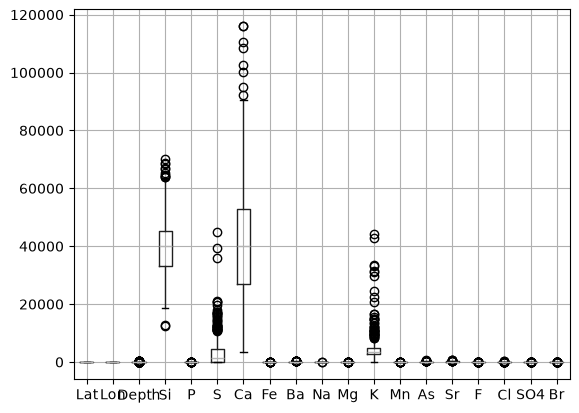

In [12]:
df.boxplot()

That boxplot was hard to see.  What if we just look at As and Fe?

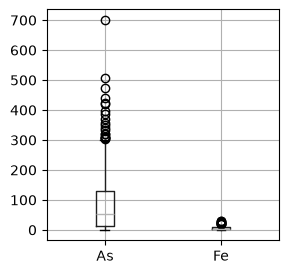

In [13]:
fig,ax=plt.subplots()
fig.set_size_inches(3,3) # no need to add this line. I am tyring to save space for printing.
df.boxplot(column=['As','Fe'],ax=ax) #ax=ax assigns the plot to your axes
plt.show()

this plotting is a little diffrent then how we have been plotting.  Pandas has some built in plotting so you can make some really nice and quick plots. But these plots are a little harder to customize. So we will be doing both types of plotting depending on the goal.  The goal could be a quick view versus a profesional looking plot.  

shape still gives us the shape.  We can call it two different ways

In [18]:
df.shape

(759, 20)

In [19]:
np.shape(df)

(759, 20)

## Stop and think for a second.  What does this shape mean?  
It means we are starting to analyze a lot of data.  It is a dataset with 759 rows or wells and 20 columns or different parameters.  This will already get hard to deal with in excel!

## We have to slow down and learn some Pandas basics.  this is a critical section.   Take your time

Now how do we get at our data.  How do we slice it.  There are many ways. lets go through them all.

.loc

.iloc

[]

.  (this is just a .)

We are going to do a lot of practice and then I tried to make a cheat sheet/table.  Take lots of notes.  

[] works like normal except you can only use integers on rows and names on columns.  you can't use integers on both rows and columns.   

I am putting .head() on the print statements to save paper. You don't need them.  It just shows the first 5 rows

In [14]:
df[:].head()  #I am including head to shorten my printouts

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
print(df['As'].head())

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64


In [16]:
print (df[:]['As'].head()) #This is the same as the one above showing the rows

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64


In [17]:
print (df[30:50]['As'])  #This prints rows 30-50.  

#Don't get confused as well_ID is our index and the name of the row

Well_ID
330     10.233204
333           NaN
342           NaN
356           NaN
374     18.365596
389     59.285003
397    115.834040
398           NaN
402     17.755544
403     81.859568
410           NaN
414           NaN
415     87.102492
417           NaN
418    386.827954
420     79.798479
421    142.409968
434           NaN
475    270.785974
478     56.883257
Name: As, dtype: float64


In [18]:
print (df[30:50:2]['As']) #we skipped by twos!

Well_ID
330     10.233204
342           NaN
374     18.365596
397    115.834040
402     17.755544
410           NaN
415     87.102492
418    386.827954
421    142.409968
475    270.785974
Name: As, dtype: float64


But you can pass a list to the columns you want! SEE the double brackets???  It is a list in the brackets!

In [19]:
df[30:50:2][['As','Depth']]

,As,Depth
Well_ID,,
330,10.233204,45
342,NaN,30
374,18.365596,45
397,115.834040,45
402,17.755544,30
410,NaN,60
415,87.102492,60
418,386.827954,65
421,142.409968,150


And the order doesn't matter.  So somehow it is smart about rows and columns

In [21]:
df[['As','Depth']][30:50:2]

,As,Depth
Well_ID,,
330,10.233204,45
342,NaN,30
374,18.365596,45
397,115.834040,45
402,17.755544,30
410,NaN,60
415,87.102492,60
418,386.827954,65
421,142.409968,150


NowI am reversing the order of the names

In [20]:
df[['Depth','As']][30:50:2]

,Depth,As
Well_ID,,
330,45,10.233204
342,30,NaN
374,45,18.365596
397,45,115.834040
402,30,17.755544
410,60,NaN
415,60,87.102492
418,65,386.827954
421,150,142.409968


What I am teaching you is easy and hard at the same time.  Take your time.  It is a lot.  I am showing you how to get at data.  I just showed you brackets and now I am going to show you .loc.  Also remember I just add .head to shorten the printouts.  you can remove it.

.loc only uses names of the index and the columns. 

THIS IS DIFFERENT.  It is saying if my index matches this name then print it. This is a little confusing our the wells have numbers for names

Sometimes I put print sometimes not. It doesn't always matter and sometimes one looks nicer than the other.  

In [21]:
df.loc[:].head()  #gives us all rows with all indexes

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
df.loc[101:156]  
#gives us all rows with all indexes but the numbers have to match an index. The numbers had to match Well_ID

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
101,24.40,90.26,60,Y,34311.71514,0.117534,2618.717799,42646.99574,1.843156,58.666191,28.281030,22.578377,NaN,1.192692,28.070949,123.043018,0.1994,38.1123,7.5180,0.0552
107,24.02,89.67,45,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0739,48.8797,27.1446,0.0304
110,23.39,91.35,45,Y,47417.95635,1.095644,113.180915,46848.09017,11.740445,131.582974,23.585986,20.501162,NaN,2.091605,96.885674,161.537333,0.1106,38.2706,0.3645,0.0403
112,24.61,91.18,60,Y,37289.99489,2.448648,13.335397,65129.07627,8.923465,134.435231,15.872622,24.259731,NaN,0.528849,80.627214,271.210408,0.2701,29.8010,NaN,NaN
116,22.96,89.77,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
130,22.94,89.97,60,N,44023.88418,1.172086,1023.167741,80183.25742,6.349396,159.171636,32.822761,27.926934,NaN,1.671612,77.006865,359.682075,0.1746,78.9229,2.6963,0.0487
153,24.17,90.81,45,Y,40523.43773,0.091676,2848.048146,40703.88184,1.869486,69.657716,29.684875,21.333230,NaN,2.291619,39.249817,173.403095,0.0716,35.8091,8.4836,0.0207
156,22.84,91.56,60,N,48375.82211,0.979053,1420.255478,52694.25919,13.020352,129.253387,23.804323,20.638614,NaN,3.111451,131.248945,232.340847,0.1152,40.7122,3.8367,0.0397


In [23]:
df.loc[101]   # just call one index.  This is well 101

Lat             24.4
Lon            90.26
Depth             60
Drink              Y
Si       34311.71514
P           0.117534
S        2618.717799
Ca       42646.99574
Fe          1.843156
Ba         58.666191
Na          28.28103
Mg         22.578377
K                NaN
Mn          1.192692
As         28.070949
Sr        123.043018
F             0.1994
Cl           38.1123
SO4            7.518
Br            0.0552
Name: 101, dtype: object

In [25]:
df.loc[102]   # if the index doesn't exist you get an error

But we can use column names

In [26]:
df.loc[:]['As'].head()

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64

Plus it can seperata with commas as well as multiple brackets

In [27]:
df.loc[:,'As'].head()

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64

You can look at the type. It shows if you just get one column then it turns from a dataframe to a series

In [28]:
print (type(df.loc[:]['As']))
print (type(df.loc[:,'As']))

<class 'pandas.Series'>
<class 'pandas.Series'>


This suble difference can sometimes be important.  A series is more like a set of values.

In [29]:
print (df.loc[330:500:2]['As']  )

Well_ID
330     10.233204
342           NaN
374     18.365596
397    115.834040
402     17.755544
410           NaN
415     87.102492
418    386.827954
421    142.409968
475    270.785974
481           NaN
488           NaN
500           NaN
Name: As, dtype: float64


We can also add a list of names

In [30]:
df.loc[330:500:2][['As','Depth']]

,As,Depth
Well_ID,,
330,10.233204,45
342,NaN,30
374,18.365596,45
397,115.834040,45
402,17.755544,30
410,NaN,60
415,87.102492,60
418,386.827954,65
421,142.409968,150


## iloc
iloc only uses integers.  So now this is row numbers. NOT the index.  look the Well_ID compared to the iloc numberss

In [31]:
df.iloc[:].head()

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
df.iloc[101:110:2] #this is row numbers now. so the index is not matching.

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
3058,23.92,90.47,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1166,110.2480,34.2441,0.0313
3060,23.62,91.56,60,Y,37199.96208,0.949837,13.694978,51862.73844,10.061950,119.569875,11.641918,19.904506,7806.94907,1.376403,154.676413,230.823815,0.2422,12.7629,0.1512,0.0201
3103,23.33,90.12,130,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3112,24.43,91.05,45,Y,41513.82677,1.697027,14.933618,47308.53575,14.961449,133.853170,22.606914,17.730658,NaN,0.913210,130.108906,182.378072,0.1951,22.9864,0.2077,0.0278
3179,23.18,90.78,50,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


and column number.  But we use a column seperator.......

In [33]:
df.iloc[101:110:2,5]

Well_ID
3058         NaN
3060    0.949837
3103         NaN
3112    1.697027
3179         NaN
Name: P, dtype: float64

In [34]:
df.iloc[101:110:2,2:5]

,Depth,Drink,Si
Well_ID,,,
3058,60,Y,NaN
3060,60,Y,37199.96208
3103,130,Y,NaN
3112,45,Y,41513.82677
3179,50,Y,NaN


Just to boggles your bind a little.....

In [35]:
df.iloc[101:110:2,[2,5,8]]  #I just had it show columns 2,5,8

,Depth,P,Fe
Well_ID,,,
3058,60,NaN,NaN
3060,60,0.949837,10.061950
3103,130,NaN,NaN
3112,45,1.697027,14.961449
3179,50,NaN,NaN


## Dot notation or Attribute Access
- Let me show you how it works
- it is easy
- Not great for progamming 

What I didn't show you is a dot notation.

In [36]:
df.As.head()

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64

Dot notation only works if you name your columns well.  No minus signs or spaces.

In [37]:
df.As[20:30]

Well_ID
233          NaN
237          NaN
275          NaN
279          NaN
280     5.364619
283          NaN
287          NaN
290          NaN
292    53.097829
295          NaN
Name: As, dtype: float64

All examples in one place so maybe we can make sense of them?



|Name                                     |Description|
|-----------------------------------------|-----------------------|
|[]||
|well_data[:]          |             all data |
|well_data[:]['As']    |            all arsenic data |
|well_data.loc[:,'As']                    |basically the same as above|
|well_data['As']                    |all arsenic data.|
|well_data[1:10]['As']              |arsenic data from rows 1-10 excluding 10|
|well_data[1:10:2]['As']            |same but skipping by two|
|well_data[1:10:2][['As','Depth']]  |for As and depth.  note the double brackets.|
|well_data[['As','Depth']][1:10:2]  |order doesn't matter|
|well_data[['Depth','As']][1:10:2]  |order doesn't matter.|  
|you can't use column numbers...................................  | |

<br/>
<br/>

|loc|Description |
|---------------------------------:|--------------------------------:|
|well_data.loc[:]  |gives us all rows with all columns|
|well_data.loc[101:156]  |needs to be an index  Gives us by index number not row number.|
|well_data.loc[101:156:2] | and we can skip|
|well_data.loc[101:156:2]['As'] | and we can do column names|
|well_data.loc[:]['As']|  |
|well_data.loc[:,'As'] | is the same as above. I have bugs where one works but other doesn't|
|well_data.loc[101:156:2][['As','Depth']]|  we can do multiple columns|
|................................................................................| .|

<br/>
<br/>

|iloc| |
|-----------------------------------------|-----------------------|
|well_data.iloc[:]                   |gives it all.|
|well_data.iloc[101:110:2]           |does row numbers.|
|well_data.iloc[101:110:2,5]         |row number by column number|
|well_data.iloc[101:110:2,2:5]        |mulitple row multiple number|
|well_data.iloc[101:110:2,[2,5,8]]    |select columns|
|...........................................................................|.|

<br/>
<br/>

|ix |phased out|
|-----------------------------------------|-----------------------|


<br/>
<br/>

|Dot notation. |This can be very nice.|
|-----------------------------------------|-----------------------|
|well_data.As       |gives all arsenic data|
|well_data.As[1:5]  |gives rows 1-5|
|...............................................................||


### You can use boolean choices to get the data you want.  For example I gave the description if people drink or don't drink from their well.  Lets count that.  

value_counts is a great first function.  It just counts for you.  Simple but very helpful.

I am going to do the same thing many different ways!  value_counts is a function that counts each 

In [38]:
df['Drink'].value_counts()

Drink
Y    614
N    144
Name: count, dtype: int64

is the same as

In [39]:
df.Drink.value_counts()

Drink
Y    614
N    144
Name: count, dtype: int64

Is the same as (I am trying to teach you pandas)

In [40]:
df.iloc[:,3].value_counts()

Drink
Y    614
N    144
Name: count, dtype: int64

Is the same as (I am trying to teach you pandas)

In [41]:
df.loc[:,'Drink'].value_counts()

Drink
Y    614
N    144
Name: count, dtype: int64

Now you should be able to access your data.  I always forget the semantics.  Look online or back at your cheat sheets.  That is why I made the cheat sheet above.

Now we can sub-select data very easily.  

We can return a boolean based on results.  

In [42]:
df['Drink']=='Y'

Well_ID
2          True
14         True
23         True
83         True
84         True
          ...  
12516      True
12654      True
72641     False
76175     False
141499    False
Name: Drink, Length: 759, dtype: bool

Also do it with the dot notation

In [43]:
df.Drink=='Y'

Well_ID
2          True
14         True
23         True
83         True
84         True
          ...  
12516      True
12654      True
72641     False
76175     False
141499    False
Name: Drink, Length: 759, dtype: bool

### THIS IS CRAZY
#### PAY ATTENTION
What if we only want data from wells people drink from?  we can ask for that.  Remember I just added the .head() to save paper

In [44]:
df[df.Drink=='Y'].head()

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


What if we only wanted arsenic concentrations where people drink the water?

This is weird again.  

You are saying only give me As.

In [45]:
df[df.Drink=='Y']['As'].head()

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64

In the crazy world of pandas where you put the Arsenic doesn't matter.

In [46]:
df['As'][df.Drink=='Y'].head()

Well_ID
2          NaN
14         NaN
23         NaN
83    78.97747
84         NaN
Name: As, dtype: float64

### THIS IS CRAZY AGAIN
#### WATCH What I am doing

Say you wanted to do an intervention.  You would want to go to the houses with the highest arsenic first.  So we could ask what are the well id's for people who drink water and their arsenic is greater than 250 ppb.  This would be poeple with high exposure!  We would need to use an and statement.  

In pandas you do this two ways.  
* np.logical_and().  
* Else you can use the & but YOU NEED PARANTHESE.  ** REMEMBER THIS!!!!!** It will come back and help you. 

We would try to convince these households to switch.  The drinking water standard is 10 ppb.  This is really crazy high exposure.

In [48]:
df['As'][(df.Drink=='Y') & (df.As>250)]

Well_ID
475     270.785974
2821    285.971884
2841    506.750798
2977    282.519542
4545    439.690000
4689    267.553524
4793    271.752307
4987    255.620635
5060    368.900000
5557    351.206317
5717    700.890000
5788    422.070000
6137    309.920000
6583    339.300000
7007    304.690000
8051    308.880000
8522    256.610000
9362    299.530000
Name: As, dtype: float64

A second way to do boolean and in pandas.  Remember.  When you split a line at a comma in a fucntion you don't need to use the \\.  I do this to make the packets print better. You don't need to do it.  But also line breaks can just make things cleaner and easier to see

In [49]:
df['As'][np.logical_and(df.Drink=='Y'
                        ,df.As>250)]

Well_ID
475     270.785974
2821    285.971884
2841    506.750798
2977    282.519542
4545    439.690000
4689    267.553524
4793    271.752307
4987    255.620635
5060    368.900000
5557    351.206317
5717    700.890000
5788    422.070000
6137    309.920000
6583    339.300000
7007    304.690000
8051    308.880000
8522    256.610000
9362    299.530000
Name: As, dtype: float64

Can we look at who drinks from their wells and if they don't drink is it beacuse it has more arsenic?

Another way to word this.

What is the average arsenic in wells people drink from?

What is the averarge arsenic in wells people don't drink from.

Use decribe....

In [47]:

#wells people drink from
print('Arsenic of wells where people drink')
print (df['As'][df.Drink=='Y'].describe() )

# wells people don't drinkfrom 
print ('\nArsenic of wells where people don\'t drink') #to put the ' in the line I added a \ before it
print (df['As'][df.Drink=='N'].describe())

Arsenic of wells where people drink
count    336.000000
mean      72.484421
std       91.571489
min        0.000000
25%        9.962403
50%       39.975000
75%       99.294435
max      700.890000
Name: As, dtype: float64

Arsenic of wells where people don't drink
count     71.000000
mean     171.105792
std      107.308224
min        1.368709
25%       81.614239
50%      150.250000
75%      250.245000
max      473.340000
Name: As, dtype: float64


What do the results above show?

I am going to come back to groupby here and there and we will do a whole packet on it.  But when your brain can think through groupby it makes things simpler.  So here we are going to groupby drink and then describe As.  It should do what we just did in one line and make a nicer output.   

In [48]:
df.groupby('Drink')['As'].describe()

,count,mean,std,min,25%,50%,75%,max
Drink,,,,,,,,
N,71.0,171.105792,107.308224,1.368709,81.614239,150.250,250.245000,473.34
Y,336.0,72.484421,91.571489,0.000000,9.962403,39.975,99.294435,700.89


### Pandas has built in ways to easily plot this data
Could we disply this data?  

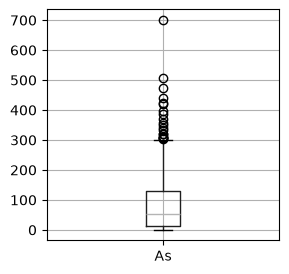

In [49]:
fig,ax=plt.subplots()
fig.set_size_inches(3,3)
df.boxplot(column='As',ax=ax)
plt.show()


Do you remember what a boxplot shows? I found this next picture on stackoverflow.  No need to import. Just for your reference.  
http://stackoverflow.com/questions/17725927/boxplots-in-matplotlib-markers-and-outliers


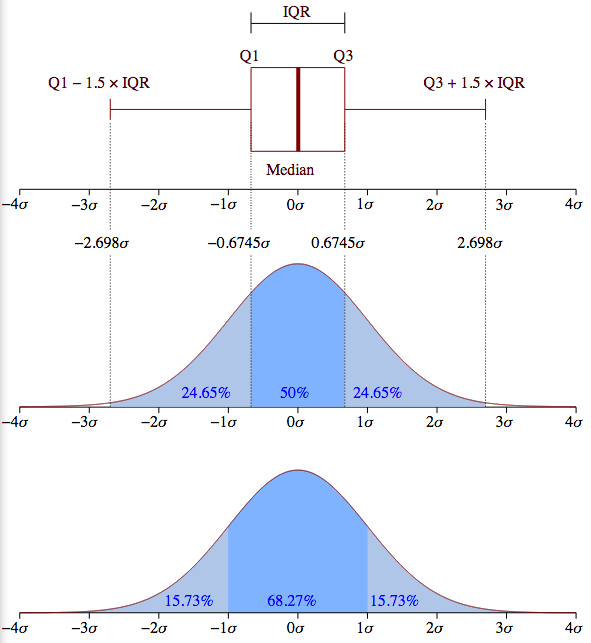

In [67]:
from IPython.display import Image
Image(filename='boxplot_structure.png',width=600)

In [50]:
df

,Lat,Lon,Depth,Drink,Si,P,S,Ca,Fe,Ba,Na,Mg,K,Mn,As,Sr,F,Cl,SO4,Br
Well_ID,,,,,,,,,,,,,,,,,,,,
2,23.74,90.31,45,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,23.62,90.60,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,23.94,91.46,60,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23.80,91.33,50,Y,48084.33842,0.936358,2085.570979,54666.48199,1.260031,96.159587,76.207449,26.104825,NaN,1.019154,78.97747,253.528674,0.1669,83.0137,5.6188,0.1512
84,23.98,90.81,150,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12516,24.71,90.41,160,Y,32379.64000,0.197380,3669.430000,39790.24000,0.341200,77.770000,26.299280,13.330000,1850.53,0.340000,0.13000,331.900000,0.3976,57.0935,10.4236,0.0391
12654,24.36,91.27,60,Y,25561.12000,0.090570,13771.370000,57630.63000,1.498350,73.230000,19.723360,33.740000,3958.51,1.200000,17.39000,215.750000,NaN,NaN,NaN,NaN
72641,24.38,90.90,45,N,31319.48000,1.162550,38.300000,60905.16000,22.417560,176.020000,14.114910,21.700000,3372.45,1.560000,112.37000,251.660000,0.2567,35.4774,0.1471,0.0363


### cool boxplots

But we really want two boxplots.  One for people who drink and one for people who don't drink.  Previously I would make you look through stack overflow for answers. But I am not sure anyone does this anymore.  

Here is how I would ask gemini for help to make the boxplot and I would drop the csv into gemini.  Plus you can paste either the raw or run version of the markdown into gemini.  Try this prompt and see if you learn how to make the graph.

- Can we read the file well_data.csv
- Can we make only one boxplot of the arsenic data which is called As and is in ppb
- But can we show the boxplots seperated by the value of drink
- can we use the fig,ax=plt.subplots nomenclature
- can we the pandas plotting functions
- do not use seaborn
- set the index to Well_ID

do the insturctions and see you can figure out how to make the boxplot.


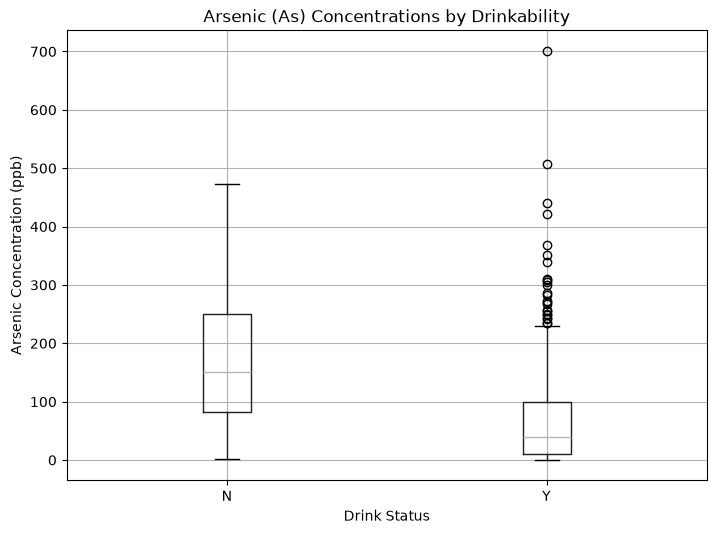

What difference do you notice about the arsenic concentrations of peeople drinking from their wells?

We are going to do a whole class on groupby.  But to see the stats you do

In [55]:
df.groupby('Drink')['As'].describe()

,count,mean,std,min,25%,50%,75%,max
Drink,,,,,,,,
N,71.0,171.105792,107.308224,1.368709,81.614239,150.250,250.245000,473.34
Y,336.0,72.484421,91.571489,0.000000,9.962403,39.975,99.294435,700.89


## Whenever you are comparing two populations a t-test should pop into your head!

# t-test or student t-test

A t-test tells you if there is a significant difference between two means.  Actually it tells you the probability that they are the same.  Back to our friend the p-value!  The [first website seems to have a good explanation](https://www.investopedia.com/terms/t/t-test.asp).

Whenever you are comparing two means you run a t-test. 

I am going to repeat this.  If you ever compare two populations with a mean you need to run a t-test to see if the differences are statistically signifcant.

You then need to choose if it is
1.  Paired [scipy.stats.ttest_rel](https://docs.scipy.org/doc/scipy-0.15.1/reference/generated/scipy.stats.ttest_rel.html)
2.  not paired [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy-0.15.1/reference/generated/scipy.stats.ttest_ind.html)

By paired we mean you repeated the measure on the same thing.  Can you track the same thing across two samples.  For example The exam score of the same person before and after an intervention 

By not paired we mean two different populations.  Imagine we fed 100 people carrots and 100 people steak and we weighed them and wanted to know if their exam scores was differnt. That is not paired and also the worst experiment ever!

In terms of our arsenic example if we measured the same wells twice it would be paired.  if we measured different sets of wells it is unpaired.  

Finally, if you are doing unpaired you need to decide if the groups have the same or unequal variance.  It is statiscally safer to choose unequal variance.  But you can always look at your variance and decide.  

Your results are a t statistic and a p-value.  We want our p-value less than 0.05 or 0.01 again!

Back to our wells.  We will run an unparied t-test with unequal variance. 

so lets pass our arrays from aboce with Arsenic for Drink=Y and Drink=N

We are asking if the difference we see with our eyes in the boxplot is statistically significant for arsenic.  You need the stats to verify!

### THIS WILL FAIL!


In [56]:
stats.ttest_ind(df['As'][df.Drink=='Y']\
                ,df['As'][df.Drink=='N'])

TtestResult(statistic=nan, pvalue=nan, df=nan)

It failed b/c we have NaN's in our data (Not a Number).  NaN's are nice as they keep track where we don't have data.  

But scipy does not handle NaN's well.  

So we need to get rid of them then do the math.  

In pandas terms we need to drop the NaN's using the function dropna

In [57]:
df['As'][df.Drink=='Y'].dropna()

Well_ID
83        78.977470
101       28.070949
110       96.885674
112       80.627214
153       39.249817
            ...    
12363     26.980000
12440     21.740000
12461    117.820000
12516      0.130000
12654     17.390000
Name: As, Length: 336, dtype: float64

So try again!

In [58]:
stats.ttest_ind(df['As'][df.Drink=='Y'].dropna()
               ,df['As'][df.Drink=='N'].dropna()
                ,equal_var=False)

TtestResult(statistic=-7.209206229150192, pvalue=1.4829579464861515e-10, df=92.74138989735245)

That is a small p-value!!!!!

So a signficant difference!  

You could say the mean arsenic concentration is lower in well where people drink then where they don't drink (p<0.01)

### Some homework hints.

for the homework you will need to make scatter plots.  They are easy to make in pandas.  Here is one of Arsenic versus Iron.  You can label your axes and change the color of your symbols.

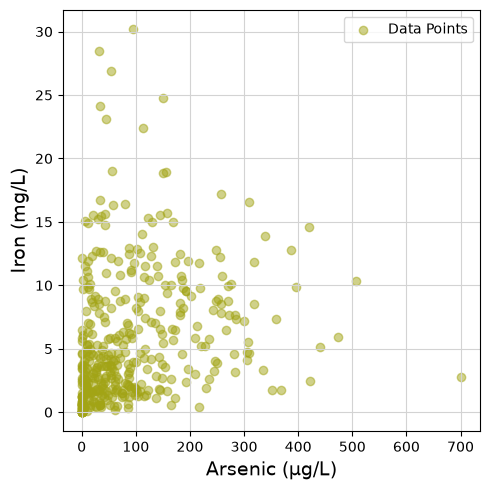

In [73]:
fig,ax=plt.subplots(layout='tight')
fig.set_size_inches(5,5)

ax.scatter(df['As'],df['Fe'],c='xkcd:vomit'
           ,label='Data Points',alpha=0.5)
ax.set_xlabel('Arsenic (µg/L)',fontsize=14)
ax.set_ylabel('Iron (mg/L)',fontsize=14)
ax.grid(True, linestyle='-', color='lightgrey')
ax.legend(loc='best')
plt.show()

If it is easier to follow you could do 

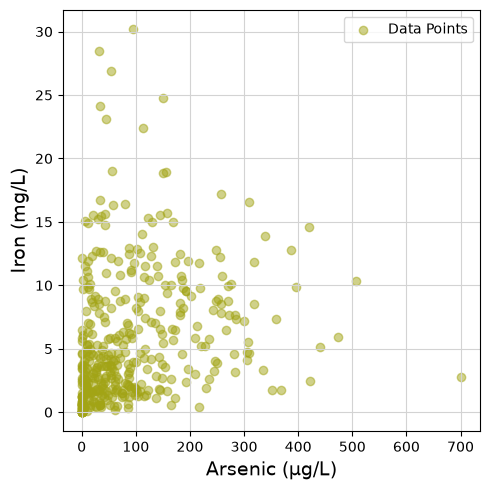

In [74]:
fig,ax=plt.subplots(layout='tight')
fig.set_size_inches(5,5)

x=df['As']
y=df['Fe']


ax.scatter(x,y,c='xkcd:vomit'
           ,label='Data Points',alpha=0.5)
ax.set_xlabel('Arsenic (µg/L)',fontsize=14)
ax.set_ylabel('Iron (mg/L)',fontsize=14)
ax.grid(True, linestyle='-', color='lightgrey')
ax.legend(loc='best')
plt.show()

### What wells do people drink from?
For our final exercise. Lets put it together and get data and then see if we can plot it.  I want to know the number of people who are drinking from there wells based on the arsenic concentrations.  Can we do the reverse.  if the arsenic is <10,10-50, and >50 what is the value counts of drinking and not drinking.  I chose these numbers because 10 ppb is the EPA and WHO drinking water limit.  50 ppb is the Bangladesh drinking water limit.  We see negative health effects at 10ppb.  Drinking water with 10 ppb arsenic is bad for you!   It increases your risk of cardiovascular disease, cancers, and death!


I used to break down the plot for you and step you through how to create it. It is a "sign of the times" but no one does that anymore.  Together Togehter Let's learn how to use AI to teach us.  We want

Three Groups
1.  <10 ppb arsenic
1.  10-50 ppb arsenic
1.  \>50 ppb arsenic

This is the graph we want to make

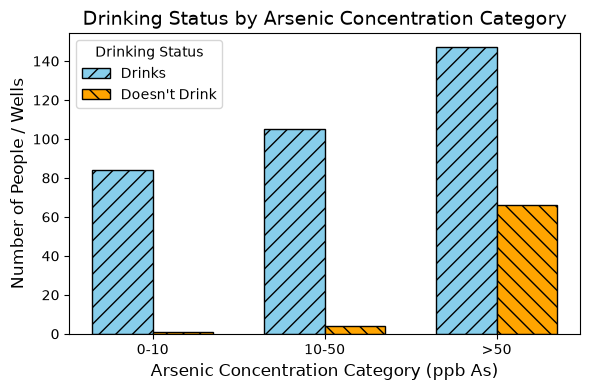

### How would I ask AI to do do this?
Here is what I submitted to gemini with the csv file.  

- Can we read the file well_data.csv and set the index to Well_ID
- I want to make a bar chart of the number of people drinking from a well but split by category of As concentrations
- I want the categories to be 0-10,10-50,>50 ppb As.
- Can we make the drink bar skyblue and doesn't drink orange.
- can we add hatching and lines around the bars. 
- can we use the fig,ax=plt.subplots nomenclature
- do not use seaborn
- can we do it only using matplotlib
- include axis labels, title, and legend


Try submitting and see what you get.  Paste the bullet points in or the markdown with the file.  Then bring the code back.

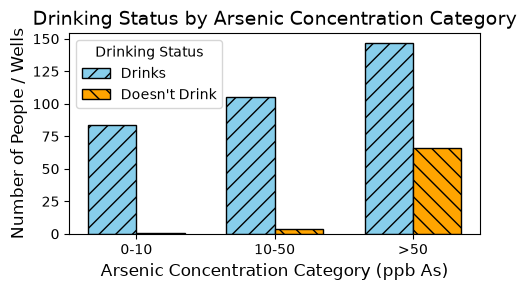

### Learn from AI
- There are two things in the code that are new to us
- pd.cut and groupby with the size and unstack.
- go back and ask AI to explain to you how they work.
- Now go and change parts of your graph
    - size
    - hatching
    - color

### Now ask AI turn it into a stacked bar chart scaled by percents
- I said
- Can we make a second bar chart of the same data but this time scaled to 100% and stacked?

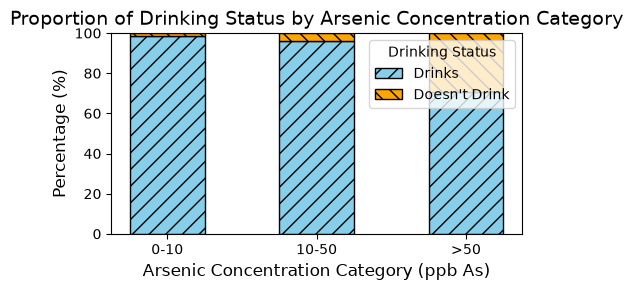

In [117]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Read well_data.csv and set index to Well_ID
df = pd.read_csv('well_data.csv', index_col='Well_ID')

# 2. Categorize As concentrations into 0-10, 10-50, and >50 ppb As
bins = [0, 10, 50, np.inf]
labels = ['0-10', '10-50', '>50']
df['As_Category'] = pd.cut(
    df['As'], bins=bins, labels=labels, include_lowest=True
)

# 3. Aggregate counts and normalize to 100%
counts = (
    df.groupby(['As_Category', 'Drink'], observed=False)
    .size()
    .unstack(fill_value=0)
)
totals = counts.sum(axis=1)
pcts = counts.div(totals, axis=0) * 100

categories = labels
drink_pct = pcts['Y']
no_drink_pct = pcts['N']

# 4. Initialize figure and axis using fig, ax = plt.subplots
fig, ax = plt.subplots(figsize=(5, 3))

width = 0.5

# 5. Plot 100% stacked bars
rects1 = ax.bar(
    categories,
    drink_pct,
    width=width,
    label='Drinks',
    color='skyblue',
    edgecolor='black',
    hatch='//',
)
rects2 = ax.bar(
    categories,
    no_drink_pct,
    width=width,
    bottom=drink_pct,
    label="Doesn't Drink",
    color='orange',
    edgecolor='black',
    hatch='\\\\',
)

# 6. Add labels, title, y-limits, and legend
ax.set_xlabel('Arsenic Concentration Category (ppb As)', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_title(
    'Proportion of Drinking Status by Arsenic Concentration Category',
    fontsize=14,
)
ax.set_ylim(0, 100)
ax.legend(title='Drinking Status', loc='upper right')

# Adjust layout and display plot
plt.tight_layout()
plt.show()

### Make it reproducible
- Can you give me the prompt I could use to make the two bar charts in a new AI chat and to save them to a file?
- Then paste the prompt below.

Here is the comprehensive prompt you can use in a new AI chat to generate both bar charts and the code to save them to files:

---

### Prompt to Copy and Paste

> Write a complete Python script using **Pandas** and **Matplotlib** only (do not use Seaborn) to analyze the dataset `well_data.csv` and generate two distinct bar charts.
> **1. Data Preparation:**
> * Read `well_data.csv` and set `Well_ID` as the DataFrame index.
> * Categorize the arsenic concentration (`As`) into three specific bins: `0-10`, `10-50`, and `>50` ppb As (ensuring 0 is included in the lowest bin).
> * Cross-tabulate the count of people who Drink (`Y`) versus Don't Drink (`N`) within each arsenic category.
> 
> 
> **2. Chart 1: Grouped Absolute Counts:**
> * Using the `fig, ax = plt.subplots()` pattern, create a grouped (side-by-side) bar chart showing the absolute number of people in each drinking category within the arsenic bins.
> * **Styling:**
> * The "Drinks" (Y) bar must be `skyblue` with diagonal hatching (`//`).
> * The "Doesn't Drink" (N) bar must be `orange` with reverse diagonal hatching (`\\`).
> * All bars must have solid black outline borders.
> 
> 
> * **Details:** Include X-axis label ("Arsenic Concentration Category (ppb As)"), Y-axis label ("Number of People / Wells"), a descriptive title, and a legend titled "Drinking Status".
> * **Output:** Save this chart to a file named `arsenic_drinking_barchart.png`.
> 
> 
> **3. Chart 2: 100% Stacked Proportions:**
> * Using the same categorical data, calculate the relative proportions scaled to 100% within each arsenic category.
> * Using the `fig, ax = plt.subplots()` pattern, create a 100% stacked bar chart.
> * **Structure:** Stack "Drinks" (Y) on the bottom and "Doesn't Drink" (N) on the top.
> * **Styling:** Retain the exact same colors (`skyblue`, `orange`), hatching patterns (`//`, `\\`), and black outline borders used in Chart 1.
> * **Details:** Include X-axis label, Y-axis label ("Percentage (%)"), a descriptive title indicating proportions, set the Y-axis limit from 0 to 100, and a legend titled "Drinking Status".
> * **Output:** Save this chart to a file named `arsenic_drinking_100pct_stacked.png`.
> 
> 
> **Final Output:** The script must conclude by running `plt.show()` for both figures.

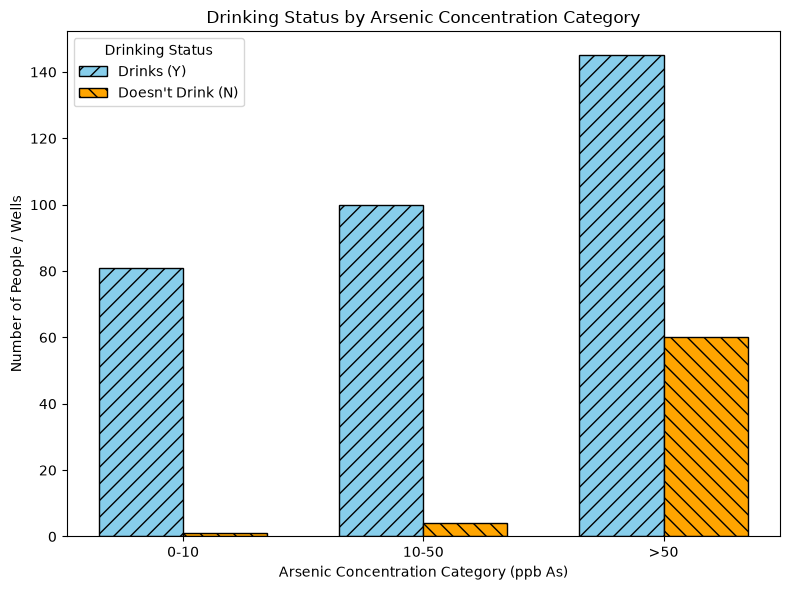

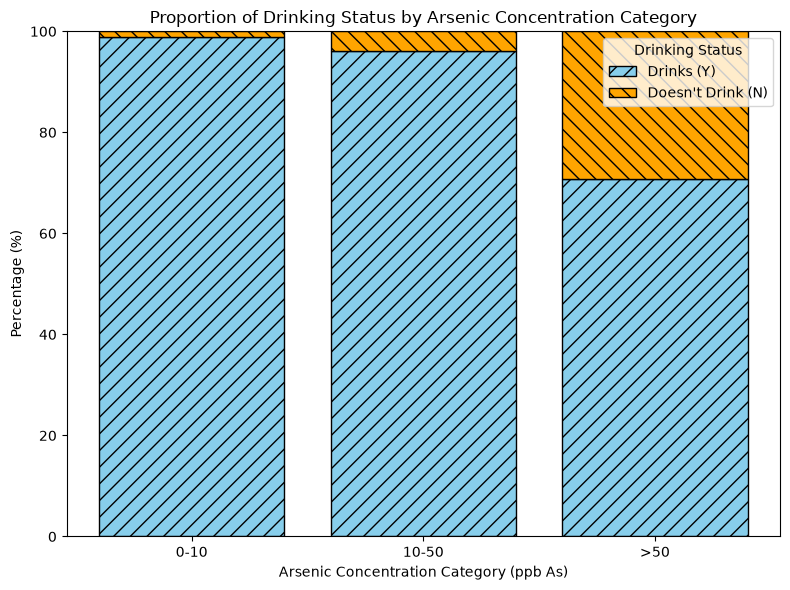

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DATA PREPARATION
# ==========================================

# Read well_data.csv and set Well_ID as DataFrame index
df = pd.read_csv('well_data.csv', index_col='Well_ID')

# Categorize arsenic concentration (As) into '0-10', '10-50', and '>50' ppb As
# setting include_lowest=True ensures 0 is included in the lowest bin
bins = [0, 10, 50, np.inf]
labels = ['0-10', '10-50', '>50']
df['As_Category'] = pd.cut(df['As'], bins=bins, labels=labels, include_lowest=True)

# Cross-tabulate count of Drinking Status ('Y' vs 'N') within each arsenic category
ct = pd.crosstab(df['As_Category'], df['Drink'])


# ==========================================
# 2. CHART 1: GROUPED ABSOLUTE COUNTS
# ==========================================

fig1, ax1 = plt.subplots(figsize=(8, 6))

x = np.arange(len(ct.index))
width = 0.35

# Side-by-side bars: Drinks (Y) on left, Doesn't Drink (N) on right
bars_y1 = ax1.bar(
    x - width / 2, 
    ct['Y'], 
    width, 
    label='Drinks (Y)', 
    color='skyblue', 
    edgecolor='black', 
    hatch='//'
)
bars_n1 = ax1.bar(
    x + width / 2, 
    ct['N'], 
    width, 
    label="Doesn't Drink (N)", 
    color='orange', 
    edgecolor='black', 
    hatch='\\\\'
)

# Axis labels, title, ticks, and legend
ax1.set_xlabel('Arsenic Concentration Category (ppb As)')
ax1.set_ylabel('Number of People / Wells')
ax1.set_title('Drinking Status by Arsenic Concentration Category')
ax1.set_xticks(x)
ax1.set_xticklabels(ct.index)
ax1.legend(title='Drinking Status')

plt.tight_layout()
fig1.savefig('arsenic_drinking_barchart.png')


# ==========================================
# 3. CHART 2: 100% STACKED PROPORTIONS
# ==========================================

# Calculate relative proportions scaled to 100% within each category
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig2, ax2 = plt.subplots(figsize=(8, 6))

# Stacked bars: Drinks (Y) at the bottom, Doesn't Drink (N) on top
bars_y2 = ax2.bar(
    ct_pct.index, 
    ct_pct['Y'], 
    label='Drinks (Y)', 
    color='skyblue', 
    edgecolor='black', 
    hatch='//'
)
bars_n2 = ax2.bar(
    ct_pct.index, 
    ct_pct['N'], 
    bottom=ct_pct['Y'], 
    label="Doesn't Drink (N)", 
    color='orange', 
    edgecolor='black', 
    hatch='\\\\'
)

# Axis labels, title, limits, and legend
ax2.set_xlabel('Arsenic Concentration Category (ppb As)')
ax2.set_ylabel('Percentage (%)')
ax2.set_title('Proportion of Drinking Status by Arsenic Concentration Category')
ax2.set_ylim(0, 100)
ax2.legend(title='Drinking Status')

plt.tight_layout()
fig2.savefig('arsenic_drinking_100pct_stacked.png')


# ==========================================
# DISPLAY FIGURES
# ==========================================

plt.show()

## Getting Versions

In [113]:
import matplotlib
import platform
import sys

# Detect macOS reliably across all Mac models
os_name = "macOS" if sys.platform == "darwin" else platform.system()

# Safely check JupyterLab version if installed in the current kernel
try:
  import jupyterlab

  jl_ver = jupyterlab.__version__
except ImportError:
  jl_ver = "4.x"  # Fallback estimate

prompt_text = (
    f"I am running Python {sys.version.split()[0]} with Matplotlib "
    f"{matplotlib.__version__} in JupyterLab {jl_ver} on {os_name}. "
    f"Please write code compatible with these versions."
)

print(prompt_text)

I am running Python 3.11.15 with Matplotlib 3.11.1 in JupyterLab 4.6.3 on macOS. Please write code compatible with these versions.


# Answers

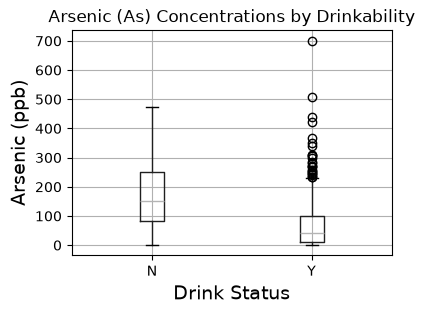

In [88]:
import matplotlib.pyplot as plt
import pandas as pd

# Read dataset and set index to Well_ID
df = pd.read_csv('well_data.csv', index_col='Well_ID')

# Create figure and axis using fig, ax nomenclature
fig, ax = plt.subplots(figsize=(4, 3))

# Generate the boxplot using pandas plotting functions grouped by 'Drink'
df.boxplot(column='As', by='Drink', ax=ax)

# Customization
plt.suptitle('')  # Removes the default pandas title
ax.set_title('Arsenic (As) Concentrations by Drinkability')
ax.set_xlabel('Drink Status',fontsize=14)
ax.set_ylabel('Arsenic (ppb)',fontsize=14)

plt.show()

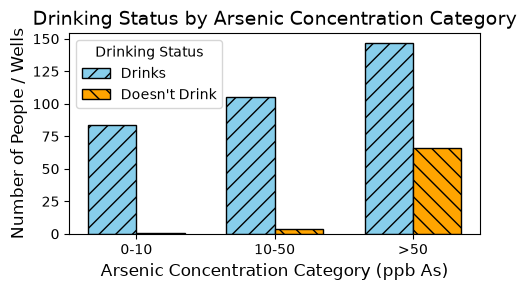

In [105]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Read well_data.csv and set index to Well_ID
df = pd.read_csv('well_data.csv', index_col='Well_ID')

# 2. Categorize As concentrations into 0-10, 10-50, and >50 ppb As
bins = [0, 10, 50, np.inf]
labels = ['0-10', '10-50', '>50']
df['As_Category'] = pd.cut(
    df['As'], bins=bins, labels=labels, include_lowest=True
)

# 3. Aggregate count of respondents/wells by category and drinking status
counts = (
    df.groupby(['As_Category', 'Drink'], observed=False)
    .size()
    .unstack(fill_value=0)
)

categories = labels
drink_counts = counts['Y']  # Drinks from well
no_drink_counts = counts['N']  # Doesn't drink from well

# Set bar positions
x = np.arange(len(categories))
width = 0.35

# 4. Initialize figure and axis using fig, ax = plt.subplots
fig, ax = plt.subplots(figsize=(5, 3))

# 5. Plot bars with skyblue and orange colors, hatching, and black border lines
rects1 = ax.bar(
    x - width / 2,
    drink_counts,
    width,
    label='Drinks',
    color='skyblue',
    edgecolor='black',
    hatch='//',
)
rects2 = ax.bar(
    x + width / 2,
    no_drink_counts,
    width,
    label="Doesn't Drink",
    color='orange',
    edgecolor='black',
    hatch='\\\\',
)

# 6. Add labels, title, ticks, and legend
ax.set_xlabel('Arsenic Concentration Category (ppb As)', fontsize=12)
ax.set_ylabel('Number of People / Wells', fontsize=12)
ax.set_title('Drinking Status by Arsenic Concentration Category', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend(title='Drinking Status')

# Adjust layout and display plot
plt.tight_layout()
plt.show()

In [121]:
##### IGNORE
import pandas as pd

# Clean CSV file
df_csv = pd.read_csv('well_data.csv')
df_csv_cleaned = df_csv.drop_duplicates(subset=['Well_ID'], keep='first')
df_csv_cleaned.to_csv('well_data.csv', index=False)

# Clean Excel file
df_xl = pd.read_excel('well_data.xlsx')
df_xl_cleaned = df_xl.drop_duplicates(subset=['Well_ID'], keep='first')
df_xl_cleaned.to_excel('well_data.xlsx', index=False)

### new page
<div style="page-break-before: always;"></div>


# Exit Ticket
## Name:
## uni:

### Q1. write down one method you could use to have pandas access a column.  


<div style="page-break-before: always;"></div>
### Ignore.  For printing to pdf.  

In [124]:
%%html
<style>
@media print {
    body {
        zoom: 0.70; /* Scales everything down to 80% of original size */
    }
}
</style>

In [125]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb \
    --log-level=CRITICAL \
    --WebPDFExporter.display_header_footer=True \
    --WebPDFExporter.header_template='<span></span>' \
    --WebPDFExporter.footer_template='<div style="font-size: 9pt; font-family: sans-serif; width: 100%; text-align: right; padding-right: 0.5in;"><span class="pageNumber"></span> of <span class="totalPages"></span></div>'

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

(True, <_io.FileIO [closed]>)

In [126]:
from io import BytesIO
import time
import ipynbname
from ipylab import JupyterFrontEnd
from pypdf import PdfReader, PdfWriter
from reportlab.pdfgen import canvas

# 1. Force JupyterLab to save latest changes
app = JupyterFrontEnd()
app.commands.execute("docmanager:save")
time.sleep(1)

# 2. Get current notebook name
filename = ipynbname.name()

# 3. Convert notebook to PDF
!uv run jupyter nbconvert --to webpdf "{filename}.ipynb" --log-level=CRITICAL

# 4. Read PDF and isolate non-setup pages
reader = PdfReader(f"{filename}.pdf")
valid_pages = reader.pages[:-2]  # Strip final page
total_pages = len(valid_pages)


# Helper function to generate page number overlay
def create_footer_overlay(page_num, total, width, height):
  packet = BytesIO()
  c = canvas.Canvas(packet, pagesize=(width, height))
  c.setFont("Helvetica", 9)
  c.setFillColorRGB(0.3, 0.3, 0.3)  # Muted grey text

  # Stamp 0.5 inches (36pt) from bottom-right corner
  c.drawRightString(width - 36, 36, f"Page {page_num} of {total}")
  c.save()
  packet.seek(0)
  return PdfReader(packet).pages[0]


# 5. Stamp numbers and build final PDF
writer = PdfWriter()
for idx, page in enumerate(valid_pages, start=1):
  w = float(page.mediabox.width)
  h = float(page.mediabox.height)

  # Stamp page number onto the current page
  overlay = create_footer_overlay(idx, total_pages, w, h)
  page.merge_page(overlay)
  writer.add_page(page)

writer.write(f"{filename}.pdf")
print(
    f"Successfully generated {filename}.pdf ({total_pages} pages with page numbers)."
)

Successfully generated Pandas_Well_Data.pdf (29 pages with page numbers).
